# FTC Merger Enforcement Analysis

**Research question:**
How has FTC merger enforcement activity changed over time
relative to HSR merger transaction volume,
and how has enforcement activity varied across industries?


**Data sources:**
1. HSR Merger Transaction
2. FTC Merger Enforcement Actions

# 1. Data Information

In [36]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

In [37]:
uploaded = files.upload()

Saving ftc_enforcement.csv to ftc_enforcement (1).csv
Saving HSR-Transactions-Filings-Second-Requests-by-FY.csv to HSR-Transactions-Filings-Second-Requests-by-FY (1).csv


In [38]:
hsr_df = pd.read_csv("HSR-Transactions-Filings-Second-Requests-by-FY.csv")
ftc_df = pd.read_csv("ftc_enforcement.csv", encoding="cp1252")

In [39]:
display(hsr_df.head())
display(ftc_df.head())

,FY,TransactionsReported,FilingsReceived,AdjustedTransactions,SecondRequestTotal,SecondRequestFTC,SecondRequestPercentFTC,SecondRequestDOJ,SecondRequestPercentDOJ,EarlyTerminationTransactions,EarlyTerminationTransactionsGranted,EarlyTerminationTransactionsNotGranted
0,1990,2262,4272,1955,89,55,0.02,34,0.01,1975,1299,676
1,1991,1529,2914,1376,64,33,0.02,31,0.02,1321,907,414
2,1992,1589,3030,1451,44,26,0.01,18,0.01,1403,1020,383
3,1993,1846,3559,1745,71,40,0.02,31,0.01,1689,1201,448
4,1994,2305,4403,2128,73,46,0.02,27,0.01,2081,1508,573


,MatterEnforcementFY,MatterEnforcementDate,MatterNumber,MatterName,MatterIndustry,Matterhyperlink,Matter Enforcement Type
0,2021,12/23/2020 0:00,1910110,E & J Gallo/Constellation Brands,Retail – Other,#https://www.ftc.gov/news-events/press-release...,Consent Order Accepted for Comment
1,2021,12/9/2020 0:00,1910134,Facebook/Instagram,Information and Technology – Software/Databases,#https://www.ftc.gov/news-events/press-release...,Permanent Injunction
2,2021,12/8/2020 0:00,2010042,Procter & Gamble/Billie,Manufacturing – Other,#https://www.ftc.gov/news-events/press-release...,Preliminary Injunction
3,2021,12/3/2020 0:00,2010044,Hackensack Merdian/Englewood,Health Care – Hospitals/Clinics,#https://www.ftc.gov/news-events/press-release...,Preliminary Injunction
4,2021,11/30/2020 0:00,2010061,CoStar Group/RentPath,Information and Technology – Other,#https://www.ftc.gov/news-events/press-release...,Preliminary Injunction


In [40]:
print("HSR rows and columns:", hsr_df.shape)
print("HSR column names:", hsr_df.columns.tolist())

print("FTC rows and columns:", ftc_df.shape)
print("FTC column names:", ftc_df.columns.tolist())

HSR rows and columns: (36, 12)
HSR column names: ['FY', 'TransactionsReported', 'FilingsReceived', 'AdjustedTransactions', 'SecondRequestTotal', 'SecondRequestFTC', 'SecondRequestPercentFTC', 'SecondRequestDOJ', 'SecondRequestPercentDOJ', 'EarlyTerminationTransactions', 'EarlyTerminationTransactionsGranted', 'EarlyTerminationTransactionsNotGranted']
FTC rows and columns: (433, 7)
FTC column names: ['MatterEnforcementFY', 'MatterEnforcementDate', 'MatterNumber', 'MatterName', 'MatterIndustry', 'Matterhyperlink', 'Matter Enforcement Type']


In [41]:
hsr_df.info()
ftc_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36 entries, 0 to 35
Data columns (total 12 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   FY                                      36 non-null     int64  
 1   TransactionsReported                    36 non-null     int64  
 2   FilingsReceived                         36 non-null     int64  
 3   AdjustedTransactions                    36 non-null     int64  
 4   SecondRequestTotal                      36 non-null     int64  
 5   SecondRequestFTC                        36 non-null     int64  
 6   SecondRequestPercentFTC                 36 non-null     float64
 7   SecondRequestDOJ                        36 non-null     int64  
 8   SecondRequestPercentDOJ                 36 non-null     float64
 9   EarlyTerminationTransactions            36 non-null     int64  
 10  EarlyTerminationTransactionsGranted     36 non-null     int64  


# 2. Cleaning the Data

In [42]:
print("HSR missing values:")
print(hsr_df.isna().sum())

print("FTC missing values:")
print(ftc_df.isna().sum())

print("HSR duplicate rows:", hsr_df.duplicated().sum())
print("FTC duplicate rows:", ftc_df.duplicated().sum())

HSR missing values:
FY                                        0
TransactionsReported                      0
FilingsReceived                           0
AdjustedTransactions                      0
SecondRequestTotal                        0
SecondRequestFTC                          0
SecondRequestPercentFTC                   0
SecondRequestDOJ                          0
SecondRequestPercentDOJ                   0
EarlyTerminationTransactions              0
EarlyTerminationTransactionsGranted       0
EarlyTerminationTransactionsNotGranted    0
dtype: int64
FTC missing values:
MatterEnforcementFY         0
MatterEnforcementDate       0
MatterNumber                0
MatterName                  0
MatterIndustry              1
Matterhyperlink            14
Matter Enforcement Type     0
dtype: int64
HSR duplicate rows: 0
FTC duplicate rows: 0


In [43]:
hsr_clean = hsr_df.copy()
ftc_clean = ftc_df.copy()

ftc_clean["MatterIndustry"] = (
    ftc_clean["MatterIndustry"].fillna("Unknown")
)

In [44]:
print(
    "Repeated matter numbers:",
    ftc_clean["MatterNumber"].duplicated().sum()
)

Repeated matter numbers: 1


In [45]:
repeated_matters = ftc_clean[
    ftc_clean["MatterNumber"].duplicated(keep=False)
]

display(repeated_matters)

,MatterEnforcementFY,MatterEnforcementDate,MatterNumber,MatterName,MatterIndustry,Matterhyperlink,Matter Enforcement Type
103,2015,2/23/2015 0:00,1410141,Novartis AG/GlaxoSmithKline,Health Care – Prescription Drugs,#https://www.ftc.gov/enforcement/cases-proceed...,Consent Order Accepted for Comment
109,2015,11/26/2014 0:00,1410141,Novartis AG/GlaxoSmithKline,Health Care – Prescription Drugs,#http://www.ftc.gov/enforcement/cases-proceedi...,Consent Order Accepted for Comment


(Not cleaning) Two records share matter number 1410141 but concern separate enforcement actions involving a consumer healthcare joint venture and an oncology business acquisition. Both records are retained in the analysis.

In [46]:
hsr_annual = hsr_df[
    ["FY", "TransactionsReported"]
].rename(columns={
    "FY": "fiscal_year",
    "TransactionsReported": "hsr_transactions"
})

In [47]:
hsr_annual = hsr_annual[
    hsr_annual["fiscal_year"].between(1996, 2020)
].copy()

# 3. Merge the Two Dataset

In [48]:
print("HSR beginning year:", hsr_df['FY'].min())
print("HSR ending year:", hsr_df["FY"].max())

print("FTC beginning year:", ftc_df['MatterEnforcementFY'].min())
print("FTC ending year:", ftc_df['MatterEnforcementFY'].max())

HSR beginning year: 1990
HSR ending year: 2025
FTC beginning year: 1996
FTC ending year: 2021


In [49]:
ftc_annual = (
    ftc_clean.groupby("MatterEnforcementFY")
    .size()
    .reset_index(name="enforcement_actions")
    .rename(columns={"MatterEnforcementFY": "fiscal_year"})
)

display(ftc_annual)

,fiscal_year,enforcement_actions
0,1996,23
1,1997,20
2,1998,26
3,1999,19
4,2000,23
5,2001,19
6,2002,17
7,2003,11
8,2004,12
9,2005,10


In [50]:
annual_df = pd.merge(
    hsr_annual,
    ftc_annual,
    on="fiscal_year",
    how="inner"
)

display(annual_df)

,fiscal_year,hsr_transactions,enforcement_actions
0,1996,3087,23
1,1997,3702,20
2,1998,4728,26
3,1999,4642,19
4,2000,4926,23
5,2001,2376,19
6,2002,1187,17
7,2003,1014,11
8,2004,1428,12
9,2005,1675,10


# 4. Annual HSR Merger Transactions, FTC enforcement actions

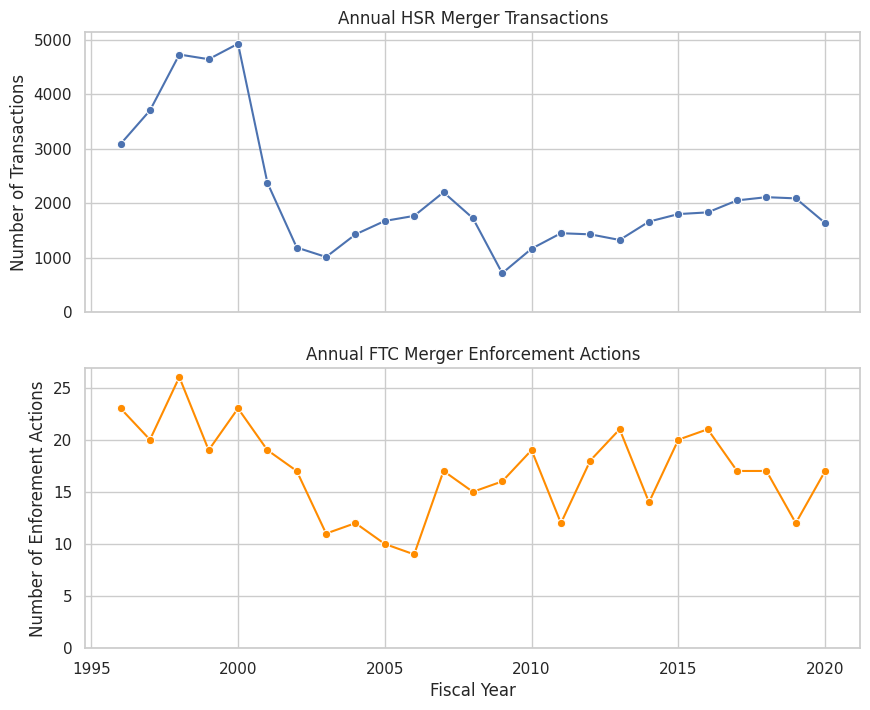

In [51]:
fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

sns.lineplot(
    data=annual_df,
    x="fiscal_year",
    y="hsr_transactions",
    marker="o",
    ax=axes[0]
)

axes[0].set_title("Annual HSR Merger Transactions")
axes[0].set_ylabel("Number of Transactions")
axes[0].set_xlabel("")
axes[0].set_ylim(bottom=0)

sns.lineplot(
    data=annual_df,
    x="fiscal_year",
    y="enforcement_actions",
    marker="o",
    color="darkorange",
    ax=axes[1]
)

axes[1].set_title("Annual FTC Merger Enforcement Actions")
axes[1].set_ylabel("Number of Enforement Actions")
axes[1].set_xlabel("Fiscal Year")
axes[1].set_ylim(bottom=0)

plt.savefig("annual_trends.png", dpi=300, bbox_inches="tight")
plt.show()

In [52]:
annual_df = annual_df.sort_values("fiscal_year")

annual_df["hsr_yoy_pct"] = (
    annual_df["hsr_transactions"].pct_change() * 100
)

annual_df["enforcement_yoy_pct"] = (
    annual_df["enforcement_actions"].pct_change() * 100
)

display(
    annual_df[
        ["fiscal_year", "hsr_yoy_pct", "enforcement_yoy_pct"]
    ].round(2)
)

,fiscal_year,hsr_yoy_pct,enforcement_yoy_pct
0,1996,NaN,NaN
1,1997,19.92,-13.04
2,1998,27.71,30.00
3,1999,-1.82,-26.92
4,2000,6.12,21.05
5,2001,-51.77,-17.39
6,2002,-50.04,-10.53
7,2003,-14.57,-35.29
8,2004,40.83,9.09
9,2005,17.30,-16.67


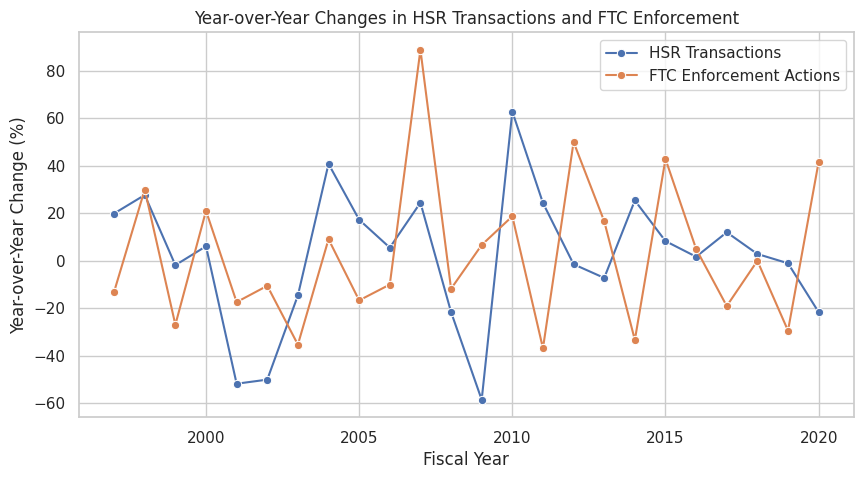

In [53]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=annual_df,
    x="fiscal_year",
    y="hsr_yoy_pct",
    marker="o",
    label="HSR Transactions"
)

sns.lineplot(
    data=annual_df,
    x="fiscal_year",
    y="enforcement_yoy_pct",
    marker="o",
    label="FTC Enforcement Actions"
)

plt.title("Year-over-Year Changes in HSR Transactions and FTC Enforcement")
plt.xlabel("Fiscal Year")
plt.ylabel("Year-over-Year Change (%)")
plt.legend()

plt.savefig("yearly_changes.png", dpi=300, bbox_inches="tight")
plt.show()

Comparing the two graphs, FTC merger enforcement activity did not consistently move in the same direction as HSR transaction volume. For example, the transaction volume decreased 1,726 to 716, while FTC enforcement activities increased slightly from 15 to 16. Compairing year-over-year percentage changes makes this difference clearer: transaction volume fell by 58.5%, while enforcement actions rose by approximately 6.7%.

# 5. FTC enforcement actions per 1,000 HSR transaction

In [54]:
annual_df["actions_per_1000_transactions"] = (
    annual_df["enforcement_actions"]
    / annual_df["hsr_transactions"]
    *1000
)

display(annual_df.round(2))

,fiscal_year,hsr_transactions,enforcement_actions,hsr_yoy_pct,enforcement_yoy_pct,actions_per_1000_transactions
0,1996,3087,23,NaN,NaN,7.45
1,1997,3702,20,19.92,-13.04,5.40
2,1998,4728,26,27.71,30.00,5.50
3,1999,4642,19,-1.82,-26.92,4.09
4,2000,4926,23,6.12,21.05,4.67
5,2001,2376,19,-51.77,-17.39,8.00
6,2002,1187,17,-50.04,-10.53,14.32
7,2003,1014,11,-14.57,-35.29,10.85
8,2004,1428,12,40.83,9.09,8.40
9,2005,1675,10,17.30,-16.67,5.97


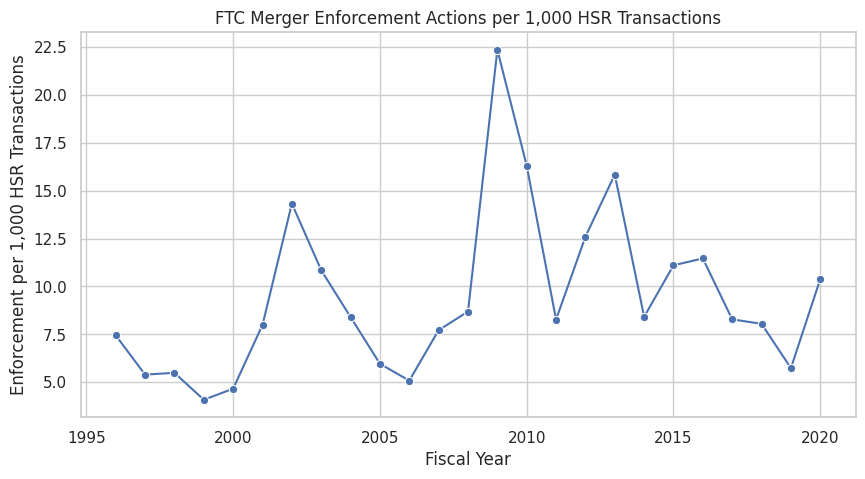

In [55]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(10,5))

sns.lineplot(
    data=annual_df,
    x="fiscal_year",
    y="actions_per_1000_transactions",
    marker="o"
)

plt.title("FTC Merger Enforcement Actions per 1,000 HSR Transactions")
plt.xlabel("Fiscal Year")
plt.ylabel("Enforcement per 1,000 HSR Transactions")

plt.savefig("enforcement_per_transaction.png", dpi=300, bbox_inches="tight")
plt.show()

FTC enforcement actions per 1,000 HSR transactions fluctuated over time, indicating that enforcement activity relative to transaction volume was not constant.

# 6. FTC Enforcement Activites across the Industries

In [56]:
ftc_analysis = ftc_clean[
    ftc_clean["MatterEnforcementFY"].between(1996, 2020)
].copy()

ftc_analysis["industry"] = (
    ftc_analysis["MatterIndustry"]
    .str.split("\u2013", n=1, regex=True)
    .str[0]
    .str.strip()
)

display(ftc_analysis[["MatterIndustry", "industry"]].head())

,MatterIndustry,industry
8,Retail – Other,Retail
9,Health Care – Other,Health Care
10,Retail – Entertainment,Retail
11,Unknown,Unknown
12,Health Care – Retail/Pharmacies,Health Care


In [57]:
sample = ftc_analysis.loc[8, "MatterIndustry"]

print(repr(sample))

for character in sample:
    if not character.isalnum() and not character.isspace():
        print(repr(character), hex(ord(character)))

'Retail – Other'
'–' 0x2013


In [58]:
industry_summary = (
    ftc_analysis["industry"]
    .value_counts()
    .reset_index()
)

industry_summary.columns = ["industry", "enforcement_actions"]

industry_summary["share_pct"] = (
    industry_summary["enforcement_actions"]
    / industry_summary["enforcement_actions"].sum()
    * 100
)

display(industry_summary.round(2))

,industry,enforcement_actions,share_pct
0,Health Care,153,36.00
1,Manufacturing,118,27.76
2,Energy,52,12.24
3,Retail,37,8.71
4,Information and Technology,28,6.59
5,Professional Services (Non Health Care),22,5.18
6,Defense,13,3.06
7,Unknown,1,0.24
8,Transportation,1,0.24


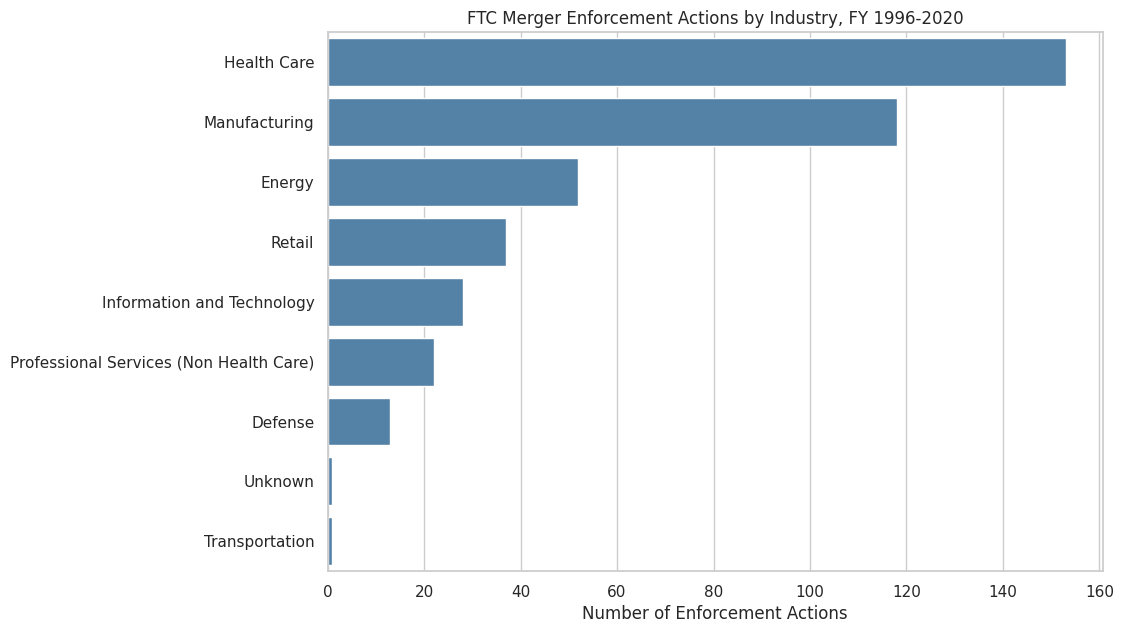

In [59]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=industry_summary,
    x="enforcement_actions",
    y="industry",
    color="steelblue"
)

plt.title("FTC Merger Enforcement Actions by Industry, FY 1996-2020")
plt.xlabel("Number of Enforcement Actions")
plt.ylabel("")

plt.savefig("industry_comparison_1.png", dpi=300, bbox_inches="tight")
plt.show()

Health care accounted for the largest number of FTC merger enforcement actions, followed by manufacturing and energy.

# 6-1. Comparison of Industry Enforcement Patterns : FY 1996 - 2007 vs. FY 2008 - 2020

In [60]:
ftc_analysis["period"] = "FY2008-2020"

ftc_analysis.loc[
    ftc_analysis["MatterEnforcementFY"] <= 2007,
    "period"
] ="FY1996-2007"

industry_period = (
    ftc_analysis.groupby(["period", "industry"])
    .size()
    .reset_index(name="enforcement_actions")
)

period_totals = industry_period.groupby("period")[
    "enforcement_actions"
].transform("sum")

industry_period["share_pct"] = (
    industry_period["enforcement_actions"]
    / period_totals
    * 100
)

display(industry_period.round(2))

,period,industry,enforcement_actions,share_pct
0,FY1996-2007,Defense,12,5.83
1,FY1996-2007,Energy,35,16.99
2,FY1996-2007,Health Care,53,25.73
3,FY1996-2007,Information and Technology,13,6.31
4,FY1996-2007,Manufacturing,60,29.13
5,FY1996-2007,Professional Services (Non Health Care),15,7.28
6,FY1996-2007,Retail,18,8.74
7,FY2008-2020,Defense,1,0.46
8,FY2008-2020,Energy,17,7.76
9,FY2008-2020,Health Care,100,45.66


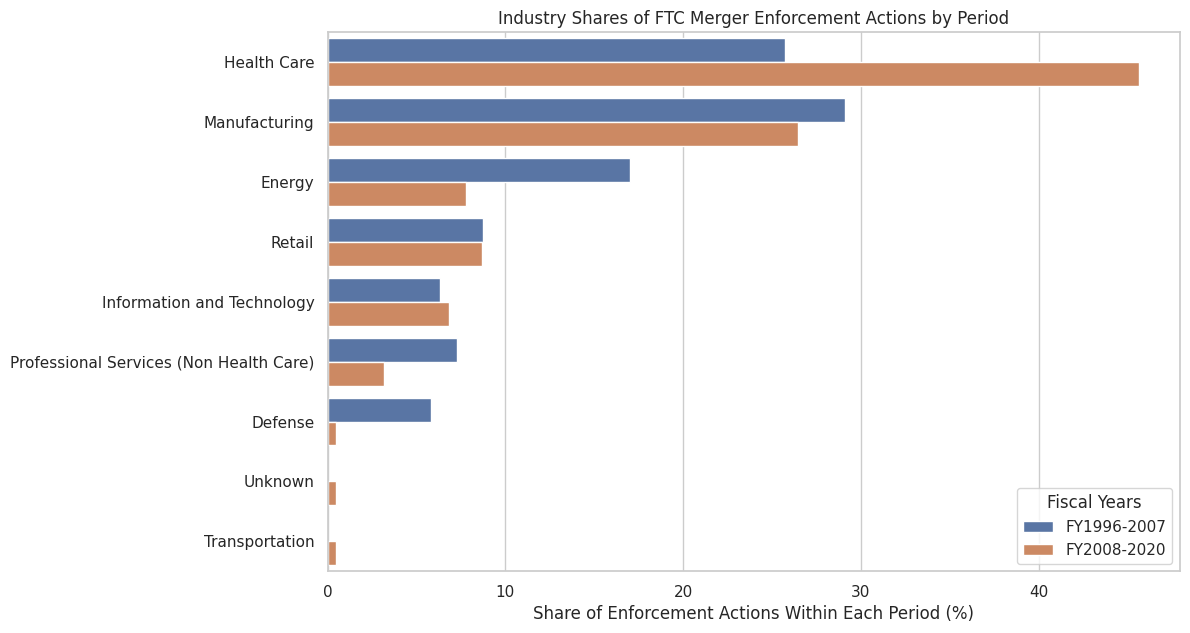

In [61]:
plt.figure(figsize=(11, 7))

sns.barplot(
    data=industry_period,
    x="share_pct",
    y="industry",
    hue="period",
    order=industry_summary["industry"].tolist(),
    hue_order=["FY1996-2007", "FY2008-2020"]
)

plt.title("Industry Shares of FTC Merger Enforcement Actions by Period")
plt.xlabel("Share of Enforcement Actions Within Each Period (%)")
plt.ylabel("")
plt.legend(title = "Fiscal Years")

plt.savefig("industry_comparison_2.png", dpi=300, bbox_inches="tight")
plt.show()

The health care sector’s share of FTC enforcement actions nearly doubled, while the shares of energy, professional services, and defense declined substantially. Other sectors’ shares remained relatively similar.

# 7. Changes of Enforcement Types

In [62]:
display(
    ftc_analysis["Matter Enforcement Type"].value_counts()
)

,count
Matter Enforcement Type,
Consent Order Accepted for Comment,346
Preliminary Injunction,63
Part III Administrative Complaint,13
Permanent Injunction,3


In [63]:
type_period = (
    ftc_analysis.groupby(["period", "Matter Enforcement Type"])
    .size()
    .reset_index(name="enforcement_actions")
)

period_totals = type_period.groupby("period")[
    "enforcement_actions"
].transform("sum")

type_period["share_pct"] = (
    type_period["enforcement_actions"]
    / period_totals
    * 100
)

display(type_period.round(2))

,period,Matter Enforcement Type,enforcement_actions,share_pct
0,FY1996-2007,Consent Order Accepted for Comment,173,83.98
1,FY1996-2007,Part III Administrative Complaint,6,2.91
2,FY1996-2007,Permanent Injunction,1,0.49
3,FY1996-2007,Preliminary Injunction,26,12.62
4,FY2008-2020,Consent Order Accepted for Comment,173,79.00
5,FY2008-2020,Part III Administrative Complaint,7,3.20
6,FY2008-2020,Permanent Injunction,2,0.91
7,FY2008-2020,Preliminary Injunction,37,16.89


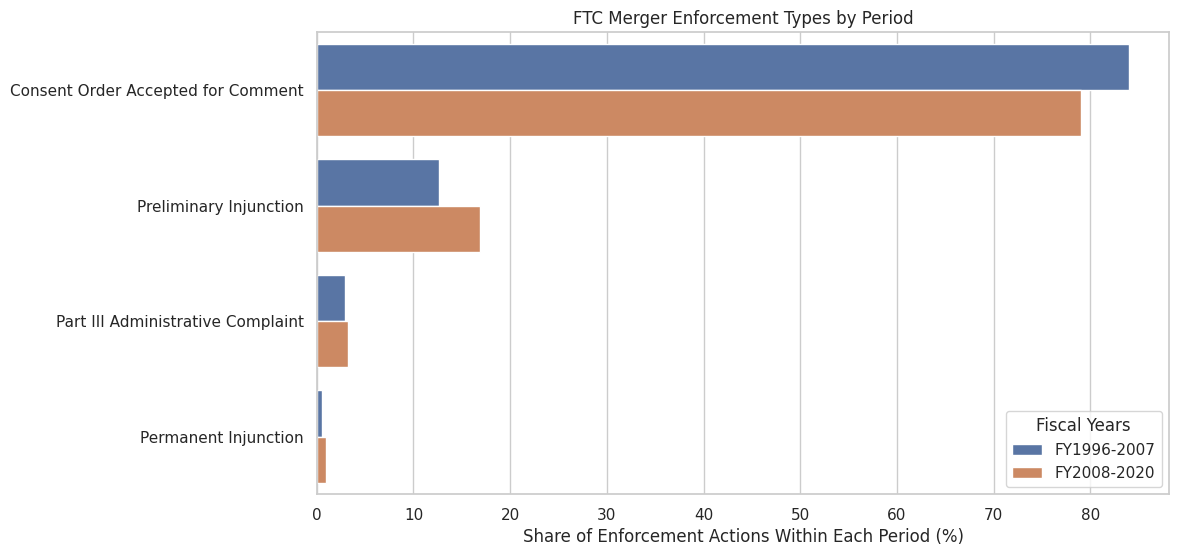

In [64]:
type_order = (
    ftc_analysis["Matter Enforcement Type"]
    .value_counts()
    .index
    .tolist()
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=type_period,
    x="share_pct",
    y="Matter Enforcement Type",
    hue="period",
    order= type_order,
    hue_order= ["FY1996-2007", "FY2008-2020"]
)

plt.title("FTC Merger Enforcement Types by Period")
plt.xlabel("Share of Enforcement Actions Within Each Period (%)")
plt.ylabel("")
plt.legend(title="Fiscal Years")

plt.savefig("enforcement_type.png", dpi=300, bbox_inches="tight")
plt.show()

The share of enforcement actions classified as “Consent Order Accepted for Comment” decreased from FY1996–2007 to FY2008–2020, while the share classified as “Preliminary Injunction” increased.

# 8. Relationship Between Annual HSR Transaction Volume and FTC Merger Enforcement Activity

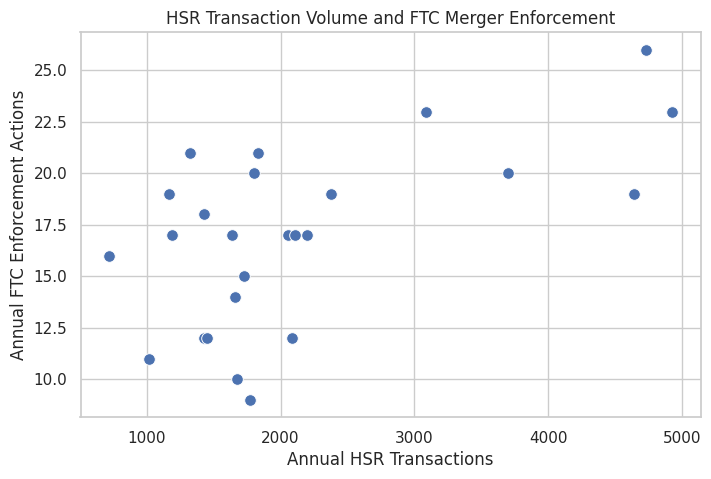

In [65]:
plt. figure(figsize=(8,5))

sns.scatterplot(
    data=annual_df,
    x="hsr_transactions",
    y="enforcement_actions",
    s=70
)

plt.title("HSR Transaction Volume and FTC Merger Enforcement")
plt.xlabel("Annual HSR Transactions")
plt.ylabel("Annual FTC Enforcement Actions")

plt.savefig("enforcement_transaction_scatterplot.png", dpi=300, bbox_inches="tight")
plt.show()

In [66]:
correlation = annual_df["hsr_transactions"].corr(
    annual_df["enforcement_actions"]
)

print("Correlation:", round(correlation, 2))

Correlation: 0.59


The correlation coefficient between annual HSR transaction volume and FTC merger enforcement actions was 0.59, indicating a moderately strong positivie linear relationship. Years with higher transaction volumes generally had more enforcement actions, although this association does not establish causation.

The initial plan was to aggregate monthly HSR data into annual totals. However, comparison with the annual dataset revealed inconsistencies in whether the monthly figures represented filings or transactions. I therefore used the annual dataset’s “TransactionsReported” variable to ensure a consistent measure of merger transaction volume.

In [67]:
hsr_clean.to_csv("hsr_cleaned.csv", index=False)
ftc_analysis.to_csv("ftc_analysis_cleaned.csv", index=False)
annual_df.to_csv("annual_analysis.csv", index=False)
industry_summary.to_csv("industry_summary.csv", index=False)
industry_period.to_csv("industry_by_period.csv", index=False)
type_period.to_csv("enforcement_types_by_period.csv", index=False)

In [68]:
import zipfile
from google.colab import files

csv_files = [
    "hsr_cleaned.csv",
    "ftc_analysis_cleaned.csv",
    "annual_analysis.csv",
    "industry_summary.csv",
    "industry_by_period.csv",
    "enforcement_types_by_period.csv"
]

with zipfile.ZipFile("cleaned_data.zip", "w") as zip_file:
    for filename in csv_files:
        zip_file.write(filename)

files.download("cleaned_data.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [69]:
data_dictionary = pd.DataFrame([
    {
        "variable": "fiscal_year",
        "description": "Fiscal year of HSR transactions or FTC enforcement actions."
    },
    {
        "variable": "hsr_transactions",
        "description": "Annual number of reported HSR transactions, from TransactionsReported."
    },
    {
        "variable": "enforcement_actions",
        "description": "Number of FTC public merger enforcement records in each year or group."
    },
    {
        "variable": "hsr_yoy_pct",
        "description": "Year-over-year percentage change in HSR transaction volume."
    },
    {
        "variable": "enforcement_yoy_pct",
        "description": "Year-over-year percentage change in FTC enforcement actions."
    },
    {
        "variable": "actions_per_1000_transactions",
        "description": "FTC enforcement actions divided by HSR transactions, multiplied by 1,000."
    },
    {
        "variable": "industry",
        "description": "Broad industry category extracted from MatterIndustry; missing values labeled Unknown."
    },
    {
        "variable": "period",
        "description": "Comparison period: FY1996-2007 or FY2008-2020."
    },
    {
        "variable": "share_pct",
        "description": "Percentage of enforcement records in a category; denominator is all records for the overall summary or within each period."
    }
])

data_dictionary.to_csv("data_dictionary.csv", index=False)
files.download("data_dictionary.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [70]:
from google.colab import files

for filename in [
    "annual_trends.png",
    "yearly_changes.png",
    "enforcement_per_transaction.png",
    "industry_comparison_1.png",
    "industry_comparison_2.png",
    "enforcement_type.png",
    "enforcement_transaction_scatterplot.png"
]:
    files.download(filename)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [71]:
readme = """# FTC Merger Enforcement and HSR Transactions

## Research Question
How has FTC merger enforcement activity changed over time relative to
HSR transaction volume, and how has enforcement varied across industries?

## Data
Source: Federal Trade Commission
https://www.ftc.gov/policy-notices/open-government/data-sets

Raw files:
- HSR-Transactions-Filings-Second-Requests-by-FY.csv
- ftc_enforcement.csv

The analysis uses TransactionsReported from the annual HSR dataset
and public FTC merger enforcement records for FY1996–2020.

Annual HSR data replaced the initially planned monthly data to use
a consistent measure of transaction volume.

## Files
- analyis.ipynb: All data cleaning and analysis code.
- data/raw/: Original datasets and source dictionaries.
- data/cleaned/: Cleaned datasets and summary tables.
- data_dictionary.csv: Definitions of derived variables.
- figures/: Analysis charts.
- Final project.pdf: Research report.

## How to Run
1. Download the repository files.
2. Open analyis.ipynb in Google Colab.
3. Run the cells in order from top to bottom.
4. At the file upload prompt, select BOTH original CSV files:
   HSR-Transactions-Filings-Second-Requests-by-FY.csv
   and ftc_enforcement.csv.
5. Continue running the remaining cells to reproduce the analysis,
   charts, and exported CSV files.

Required Python libraries: pandas, matplotlib, and seaborn.

## Analysis
Annual trends, year-over-year percentage changes, enforcement actions
per 1,000 HSR transactions, industry shares, enforcement type shares,
and Pearson correlation.

Period comparisons cover FY1996–2007 and FY2008–2020.

## Limitations
Actions per 1,000 transactions is a descriptive ratio, not an individual
transaction's probability of enforcement. Transaction reporting and
enforcement may occur in different years.

Industry comparisons show enforcement shares because industry-level
HSR transaction counts are unavailable. Correlation does not establish
causation.
"""

with open("README.md", "w", encoding="utf-8") as f:
    f.write(readme)

from google.colab import files
files.download("README.md")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>